---
format:
  html:
    code-fold: true
    embed-resources: true
---

# Intro to Machine Learning; Linear Regression Models

In [4]:
import pandas as pd
from plotnine import ggplot, aes, geom_point, geom_smooth, geom_line, labs, scale_x_continuous, theme_minimal
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

## Music Challenge

Which popular songs from the past will be recognized by future generations, and which will fade into obscurity? The website [The Pudding](https://pudding.cool/) conducts the [Music Challenge](https://pudding.cool/2020/04/music-challenge/) where they ask thousands of people whether they recognize hit songs from the past. We'll look at some of the [data](https://github.com/the-pudding/song-decay-clean/tree/master/src/assets/data) related to the article ["Defining the 90s Music Canon"](https://pudding.cool/2020/07/song-decay/).

The data set at https://raw.githubusercontent.com/the-pudding/song-decay-clean/refs/heads/master/src/assets/data/lollipop_chart_data_july_13.csv contains 344 songs released in the 1990s. For each song, the proportion of survey respondents who recognized the song is recorded, for both Millennial respondents and Gen Z respondents. Our goal will be to use linear regression to **predict the Gen Z recognition**.

We will try several different linear regression models. Save each of your models with a different name because you will compare them at the end.



0. Read in the data and describe the Gen Z recognition variable.

In [5]:
df = pd.read_csv("https://raw.githubusercontent.com/the-pudding/song-decay-clean/refs/heads/master/src/assets/data/lollipop_chart_data_july_13.csv")
df.head()
#df["mean_gen_z_recognition"].describe()

,artist_song,mean_millennial_recognition,mean_gen_z_recognition
0,2 Pac|||California Love,0.517602,0.268378
1,2Pac|||How Do U Want It,0.209632,0.062439
2,702|||Where My Girls At?,0.553481,0.244176
3,Ace Of Base|||All That She Wants,0.830967,0.540097
4,Ace Of Base|||Don't Turn Around,0.623149,0.372787


1. Use scikit-learn to fit a linear regression model for predicting Gen Z recognition from Millennial recognition.

In [6]:
X = df[["mean_millennial_recognition"]]          # double brackets -> DataFrame (2-D)
y = df["mean_gen_z_recognition"]         # single brackets -> Series (1-D)
print(type(X).__name__, X.shape, "|", type(y).__name__, y.shape)

DataFrame (344, 1) | Series (344,)


In [7]:
model_genz = LinearRegression()
model_genz.fit(X, y)
print("intercept:", round(model_genz.intercept_, 4))
print("coef:     ", model_genz.coef_.round(4))
print("R²:       ", round(model_genz.score(X, y), 3))

intercept: -0.0481
coef:      [0.7067]
R²:        0.797


2. Make a scatterplot of Gen Z recognition versus Millennial recognition, and overlay a graph of the fitted model from the previous part.

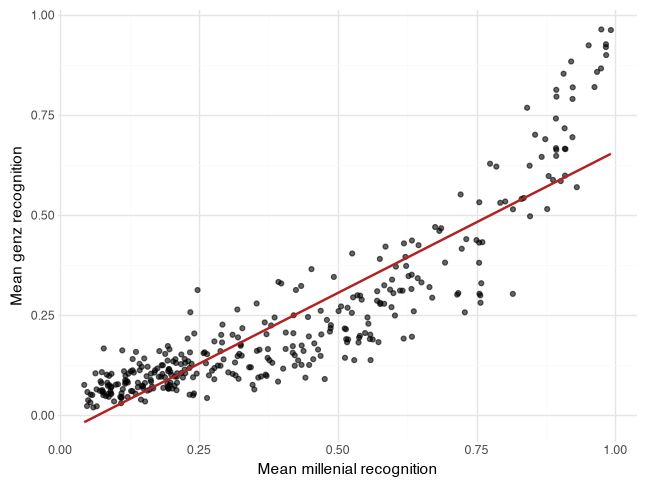

In [8]:
(ggplot(df, aes(x="mean_millennial_recognition", y="mean_gen_z_recognition"))
 + geom_point(alpha=0.6)
 + geom_smooth(method="lm", se=False, color="firebrick")
 + labs(x="Mean millenial recognition", y="Mean genz recognition")
 + theme_minimal())

3. Explain why you might want to consider taking a log of Gen Z recognition. Then use scikit-learn to fit a linear regression model for predicting log of Gen Z recognition from Millennial recognition.

There is a curve in the data, so the line doesn't really capture the full pattern. Taking the log of the response can turn a multiplicative/curved pattern into a relationship that is closer to linear.

In [9]:
X_log = df[["mean_millennial_recognition"]]
y_log = np.log(df["mean_gen_z_recognition"])

model_log_genz = LinearRegression().fit(X_log, y_log)

print("intercept:", round(model_log_genz.intercept_, 4))
print(pd.Series(model_log_genz.coef_, index=X_log.columns).round(5))
print("R²:", round(model_log_genz.score(X_log, y_log), 3))

intercept: -2.9083
mean_millennial_recognition    2.79917
dtype: float64
R²: 0.823


4. Make a scatterplot of Gen Z recognition versus Millennial recognition, and overlay a graph of the fitted model from the previous part.

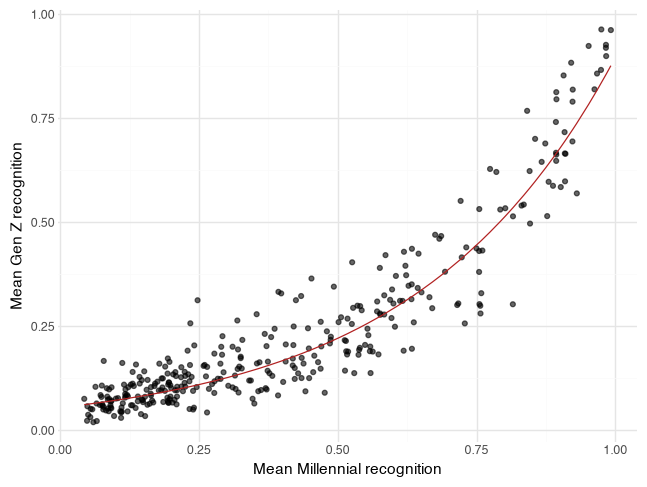

In [10]:
plot_df = df.sort_values("mean_millennial_recognition").copy()
plot_df["pred_gen_z_recognition"] = np.exp(
    model_log_genz.predict(plot_df[["mean_millennial_recognition"]])
)

(ggplot(plot_df, aes(x="mean_millennial_recognition", y="mean_gen_z_recognition"))
 + geom_point(alpha=0.6)
 + geom_line(aes(y="pred_gen_z_recognition"), color="firebrick")
 + labs(x="Mean Millennial recognition", y="Mean Gen Z recognition")
 + theme_minimal())

5. Now we'll try a polynomial model for predicting Gen Z recognition from Millennial recognition. Use scikit-learn to fit a model with two features: Millennial recognition and its square.

In [11]:
df["millennial_recognition_squared"] = df["mean_millennial_recognition"] ** 2

X_square = df[["mean_millennial_recognition", "millennial_recognition_squared"]]
y = df["mean_gen_z_recognition"]

square_model = LinearRegression().fit(X_square, y)

print("intercept:", round(square_model.intercept_, 4))
print(pd.Series(square_model.coef_, index=X_square.columns).round(5))
print("R²:", round(square_model.score(X_square, y), 3))

intercept: 0.1085
mean_millennial_recognition      -0.27264
millennial_recognition_squared    1.02072
dtype: float64
R²: 0.898


In [12]:
square_model.coef_, square_model.intercept_

(array([-0.27263527,  1.02072241]), np.float64(0.10851294576257645))

6. Make a scatterplot of Gen Z recognition versus Millennial recognition, and overlay a graph of the fitted model.

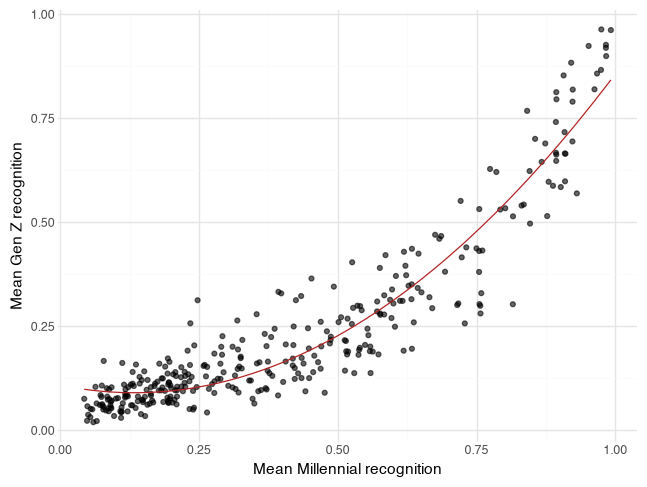

In [13]:
plot_df = df.sort_values("mean_millennial_recognition").copy()

plot_df["pred_gen_z_recognition"] = square_model.predict(
    plot_df[["mean_millennial_recognition", "millennial_recognition_squared"]]
)

(ggplot(plot_df, aes(x="mean_millennial_recognition", y="mean_gen_z_recognition"))
 + geom_point(alpha=0.6)
 + geom_line(aes(y="pred_gen_z_recognition"), color="firebrick")
 + labs(x="Mean Millennial recognition", y="Mean Gen Z recognition")
 + theme_minimal())

7. Choose one of your favorite songs that is in the data set. Use each model to predict the Gen Z recognition for the song. Which model gives the best prediction?

I like the song "Genie in a Bottle"by Christina Aguilera. 

In [14]:
song = df[df["artist_song"].str.contains("Genie in a Bottle", case=False, na=False)].copy()

X_song = song[["mean_millennial_recognition"]]
X_song_square = song[["mean_millennial_recognition", "millennial_recognition_squared"]]
actual = song["mean_gen_z_recognition"].iloc[0]

predictions = pd.Series({
    "linear": model_genz.predict(X_song)[0],
    "log model": np.exp(model_log_genz.predict(X_song)[0]),
    "polynomial": square_model.predict(X_song_square)[0]
})

comparison = pd.DataFrame({"prediction": predictions, "actual": actual})
comparison["absolute_error"] = (comparison["prediction"] - actual).abs()

print(comparison.round(3))
print("Best model:", comparison["absolute_error"].idxmin())

            prediction  actual  absolute_error
linear           0.604   0.694           0.090
log model        0.722   0.694           0.028
polynomial       0.726   0.694           0.032
Best model: log model


8. The song "Smells Like Teen Spirit" by Nirvana is inexplicably not included in the data set. Suppose the Millenial recognition of this song is 0.7. Use each model to predict the Gen Z recognition for this song. Which model gives the best prediction?

In [16]:
new_song = pd.DataFrame({"mean_millennial_recognition": [0.7]})
new_song_square = new_song.assign(
    millennial_recognition_squared=new_song["mean_millennial_recognition"] ** 2
)

predictions = pd.Series({
    "linear": model_genz.predict(new_song)[0],
    "log model": np.exp(model_log_genz.predict(new_song)[0]),
    "polynomial": square_model.predict(new_song_square)[0]
})

print(predictions.round(3))


linear        0.447
log model     0.387
polynomial    0.418
dtype: float64


## Categorical Predictors (FEV data)

Do non-smokers have better lungs than smokers? One measure of lung function is forced expiratory volume (FEV), the amount of air (in liters) an individual can exhale in the first second of forceful breath.  Larger values of FEV are indicative of better functioning lungs. In a study, FEV was measured for a group of 654 subjects, along with whether or not they smoked and other variables.

In [17]:
df_fev = pd.read_csv("https://raw.githubusercontent.com/kevindavisross/data301/refs/heads/main/data/FEV.csv")

df_fev

,ID,Smoking status,FEV,Height,Age (months)
0,201,non-smoker,2.884,69.0,132
1,202,non-smoker,2.328,64.0,120
2,301,non-smoker,1.708,57.0,108
3,341,non-smoker,3.381,63.0,172
4,351,non-smoker,2.170,58.0,130
...,...,...,...,...,...
649,83841,non-smoker,2.115,50.0,58
650,83901,non-smoker,2.328,60.0,98
651,83951,smoker,3.069,65.0,130
652,83952,non-smoker,1.495,57.0,85


1\. First fit a regression model with a single predictor: Smoking status. Since this variable is categorical you need to "dummify" it before fitting the model.

In [18]:
X_fev = pd.get_dummies(
    df_fev[["Smoking status"]], drop_first=True
).astype(int)

y_fev = df_fev["FEV"]

model_fev_1 = LinearRegression().fit(X_fev, y_fev)

print("intercept:", round(model_fev_1.intercept_, 4))
print(pd.Series(model_fev_1.coef_, index=X_fev.columns).round(5))
print("R²:", round(model_fev_1.score(X_fev, y_fev), 3))

intercept: 2.5661
Smoking status_smoker    0.71072
dtype: float64
R²: 0.06


2\. What are the predictions from this model? How could we have known that those would be the predictions?

In [19]:
new_status = pd.DataFrame({"Smoking status": ["non-smoker", "smoker"]})

X_new_status = pd.get_dummies(new_status, drop_first=True).astype(int)
X_new_status = X_new_status.reindex(columns=X_fev.columns, fill_value=0)

new_status["predicted_FEV"] = model_fev_1.predict(X_new_status)
print(new_status.round(3))

# With one categorical predictor, each fitted value equals that group's sample mean.
print(df_fev.groupby("Smoking status")["FEV"].mean().round(3))

  Smoking status  predicted_FEV
0     non-smoker          2.566
1         smoker          3.277
Smoking status
non-smoker    2.566
smoker        3.277
Name: FEV, dtype: float64


We knew the intercept in the model was the non-smoker predicted FEV and for the smoker predicted FEV you add the intercept and the coefficient for smoking. 

3\. Look at the results for the previous parts. What do you notice? Is this what you expected? Remember: larger FEV means better lungs - who tends to have larger FEV, smokers or non-smokers?

Smokers have a higher average FEV than non-smokers, which is surprising because smoking harms lungs. I thought it would be the opposite way. 

4\. Suggest some explanations for why smokers tend to have *higher* FEV than non-smokers?

This could be because smokers in the data tend to be older, and older children naturally have higher FEV. It makes it seem like the people who smoke have higher FEV but it may be due to age. 

5\. Fit a linear regression model with two predictors: smoking status and Age (and no interaction).

In [20]:
X_fev_2 = pd.get_dummies(
    df_fev[["Smoking status"]], drop_first=True
).astype(int)

X_fev_2["Age (months)"] = df_fev["Age (months)"]

model_fev_2 = LinearRegression().fit(X_fev_2, y_fev)

print("intercept:", round(model_fev_2.intercept_, 4))
print(pd.Series(model_fev_2.coef_, index=X_fev_2.columns).round(5))
print("R²:", round(model_fev_2.score(X_fev_2, y_fev), 3))

intercept: 0.3681
Smoking status_smoker   -0.21718
Age (months)             0.01921
dtype: float64
R²: 0.576


6\. Make a scatterplot of FEV versus Age, colored by smoking status, and overlay a graph of the fitted model.

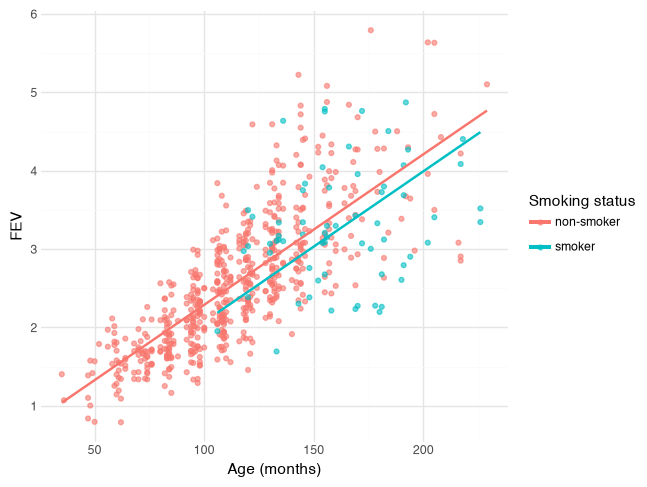

In [21]:
plot_df = df_fev.sort_values(["Smoking status", "Age (months)"]).copy()

X_plot = pd.get_dummies(plot_df[["Smoking status"]], drop_first=True).astype(int)
X_plot["Age (months)"] = plot_df["Age (months)"]
X_plot = X_plot.reindex(columns=X_fev_2.columns, fill_value=0)

plot_df["predicted_FEV"] = model_fev_2.predict(X_plot)

(ggplot(plot_df, aes(x="Age (months)", y="FEV", color="Smoking status"))
 + geom_point(alpha=0.6)
 + geom_line(aes(y="predicted_FEV"), size=1)
 + labs(x="Age (months)", y="FEV")
 + theme_minimal())

7\. Fit a linear regression model with predictors smoking status, Age, and their interaction.

In [22]:
X_fev_3 = X_fev_2.copy()

smoker_dummy = X_fev.columns[0]
X_fev_3["smoker_x_age"] = X_fev_3[smoker_dummy] * X_fev_3["Age (months)"]

model_fev_3 = LinearRegression().fit(X_fev_3, y_fev)

print("intercept:", round(model_fev_3.intercept_, 4))
print(pd.Series(model_fev_3.coef_, index=X_fev_3.columns).round(5))
print("R²:", round(model_fev_3.score(X_fev_3, y_fev), 3))

intercept: 0.2595
Smoking status_smoker    1.87006
Age (months)             0.02016
smoker_x_age            -0.01311
dtype: float64
R²: 0.592


8\. Make a scatterplot of FEV versus Age, colored by smoking status, and overlay a graph of the fitted model.

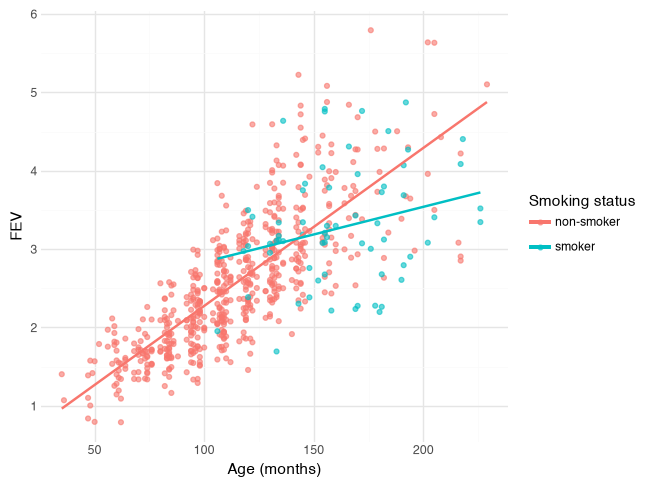

In [23]:
plot_df = df_fev.sort_values(["Smoking status", "Age (months)"]).copy()

X_plot = pd.get_dummies(plot_df[["Smoking status"]], drop_first=True).astype(int)
X_plot["Age (months)"] = plot_df["Age (months)"]
X_plot["smoker_x_age"] = X_plot[smoker_dummy] * X_plot["Age (months)"]
X_plot = X_plot.reindex(columns=X_fev_3.columns, fill_value=0)

plot_df["predicted_FEV"] = model_fev_3.predict(X_plot)

(ggplot(plot_df, aes(x="Age (months)", y="FEV", color="Smoking status"))
 + geom_point(alpha=0.6)
 + geom_line(aes(y="predicted_FEV"), size=1)
 + labs(x="Age (months)", y="FEV")
 + theme_minimal())

9\. Compare the models. Which do you think is "best"? Why? How could you investigate?

The no-interaction model is probably best, because the interaction model only improves R^2 slightly. The one without the interaction is more simple and less likely to overfit. We could also test their RMSE and choose the model with the lower standard error. 